# Sameer Ramkissoon NYIT DTSC-710 M01 Machine Learning
# Project 1 - Predicting House Prices Using Multiple Linear Regression
Predicting house prices based on several house features using multiple linear regression and evaluate its performance.

In [1]:
# Imports
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, root_mean_squared_error, r2_score

## Section 1: Exploring Dataset
- Loading dataset
- Summary statistics, shape, description

In [2]:
df = pd.read_csv('data.csv')
np.set_printoptions(precision=2)

In [3]:
dimensions = df.shape
print(f"{dimensions[0]} Rows X {dimensions[1]} Columns")

4600 Rows X 18 Columns


In [4]:
df.head(5)

,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,sqft_above,sqft_basement,yr_built,yr_renovated,street,city,statezip,country
0,2014-05-02 00:00:00,313000.0,3.0,1.50,1340,7912,1.5,0,0,3,1340,0,1955,2005,18810 Densmore Ave N,Shoreline,WA 98133,USA
1,2014-05-02 00:00:00,2384000.0,5.0,2.50,3650,9050,2.0,0,4,5,3370,280,1921,0,709 W Blaine St,Seattle,WA 98119,USA
2,2014-05-02 00:00:00,342000.0,3.0,2.00,1930,11947,1.0,0,0,4,1930,0,1966,0,26206-26214 143rd Ave SE,Kent,WA 98042,USA
3,2014-05-02 00:00:00,420000.0,3.0,2.25,2000,8030,1.0,0,0,4,1000,1000,1963,0,857 170th Pl NE,Bellevue,WA 98008,USA
4,2014-05-02 00:00:00,550000.0,4.0,2.50,1940,10500,1.0,0,0,4,1140,800,1976,1992,9105 170th Ave NE,Redmond,WA 98052,USA


In [5]:
# info of each attribute
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4600 entries, 0 to 4599
Data columns (total 18 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   date           4600 non-null   str    
 1   price          4600 non-null   float64
 2   bedrooms       4600 non-null   float64
 3   bathrooms      4600 non-null   float64
 4   sqft_living    4600 non-null   int64  
 5   sqft_lot       4600 non-null   int64  
 6   floors         4600 non-null   float64
 7   waterfront     4600 non-null   int64  
 8   view           4600 non-null   int64  
 9   condition      4600 non-null   int64  
 10  sqft_above     4600 non-null   int64  
 11  sqft_basement  4600 non-null   int64  
 12  yr_built       4600 non-null   int64  
 13  yr_renovated   4600 non-null   int64  
 14  street         4600 non-null   str    
 15  city           4600 non-null   str    
 16  statezip       4600 non-null   str    
 17  country        4600 non-null   str    
dtypes: float64(4), int6

In [6]:
# summary stats for numeric values
df.describe()

,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,sqft_above,sqft_basement,yr_built,yr_renovated
count,4.600000e+03,4600.000000,4600.000000,4600.000000,4.600000e+03,4600.000000,4600.000000,4600.000000,4600.000000,4600.000000,4600.000000,4600.000000,4600.000000
mean,5.519630e+05,3.400870,2.160815,2139.346957,1.485252e+04,1.512065,0.007174,0.240652,3.451739,1827.265435,312.081522,1970.786304,808.608261
std,5.638347e+05,0.908848,0.783781,963.206916,3.588444e+04,0.538288,0.084404,0.778405,0.677230,862.168977,464.137228,29.731848,979.414536
min,0.000000e+00,0.000000,0.000000,370.000000,6.380000e+02,1.000000,0.000000,0.000000,1.000000,370.000000,0.000000,1900.000000,0.000000
25%,3.228750e+05,3.000000,1.750000,1460.000000,5.000750e+03,1.000000,0.000000,0.000000,3.000000,1190.000000,0.000000,1951.000000,0.000000
50%,4.609435e+05,3.000000,2.250000,1980.000000,7.683000e+03,1.500000,0.000000,0.000000,3.000000,1590.000000,0.000000,1976.000000,0.000000
75%,6.549625e+05,4.000000,2.500000,2620.000000,1.100125e+04,2.000000,0.000000,0.000000,4.000000,2300.000000,610.000000,1997.000000,1999.000000
max,2.659000e+07,9.000000,8.000000,13540.000000,1.074218e+06,3.500000,1.000000,4.000000,5.000000,9410.000000,4820.000000,2014.000000,2014.000000


In [7]:
# no nulls
df.isnull().sum()

date             0
price            0
bedrooms         0
bathrooms        0
sqft_living      0
sqft_lot         0
floors           0
waterfront       0
view             0
condition        0
sqft_above       0
sqft_basement    0
yr_built         0
yr_renovated     0
street           0
city             0
statezip         0
country          0
dtype: int64

## Section 2: Data Visualization 
- House price histogram
- Finding the outliers
- Scatter plot of price vs living area, bedrooms, bathrooms
- Correlation heatmap

### 2.1 House Price Distribution

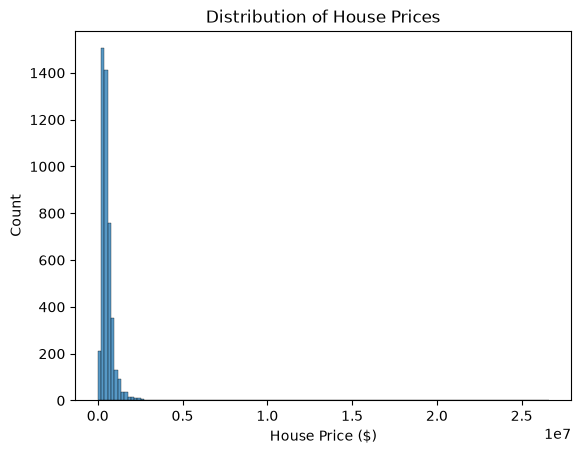

In [8]:
# Histogram of house prices
price_hist = sns.histplot(x='price', data=df)
price_hist.set_title("Distribution of House Prices")
price_hist.set(xlabel="House Price ($)", ylabel="Count")

plt.show()

### Calculating the outliers and showing percentage it makes up in full dataset

In [9]:
# Calculating outlier function
def calc_outliers(col):
    twenty_fifth = col.quantile(0.25)
    seventy_fifth = col.quantile(0.75)
    iqr = seventy_fifth - twenty_fifth

    upper = seventy_fifth + (1.5 * iqr)
    lower = twenty_fifth - (1.5 * iqr)

    return upper, lower

In [10]:
# Getting the outliers for the data (before feature selection & trimming)
thresholds = calc_outliers(df['price'])

outlier_data = df[(df['price'] > thresholds[0]) | (df['price'] < thresholds[1]) | (df['price'] < 1)]
outlier_data.head()

,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,sqft_above,sqft_basement,yr_built,yr_renovated,street,city,statezip,country
1,2014-05-02 00:00:00,2384000.0,5.0,2.50,3650,9050,2.0,0,4,5,3370,280,1921,0,709 W Blaine St,Seattle,WA 98119,USA
11,2014-05-02 00:00:00,1400000.0,4.0,2.50,2920,4000,1.5,0,0,5,1910,1010,1909,1988,3838-4098 44th Ave NE,Seattle,WA 98105,USA
14,2014-05-02 00:00:00,1200000.0,5.0,2.75,2910,9480,1.5,0,0,3,2910,0,1939,1969,3534 46th Ave NE,Seattle,WA 98105,USA
99,2014-05-05 00:00:00,1395000.0,5.0,3.50,4010,8510,2.0,0,1,5,2850,1160,1971,0,3930 NE Belvoir Pl,Seattle,WA 98105,USA
122,2014-05-05 00:00:00,2280000.0,7.0,8.00,13540,307752,3.0,0,4,3,9410,4130,1999,0,26408 NE 70th St,Redmond,WA 98053,USA


In [11]:
print(f"Outliers: {len(outlier_data)}")
print(f"Percentage Outliers: {round(100 * len(outlier_data)/len(df),2)}%")

Outliers: 289
Percentage Outliers: 6.28%


### 2.2 Scatter Plots
- Price vs bedrooms
- Price vs bathrooms
- Price vs living space square footage

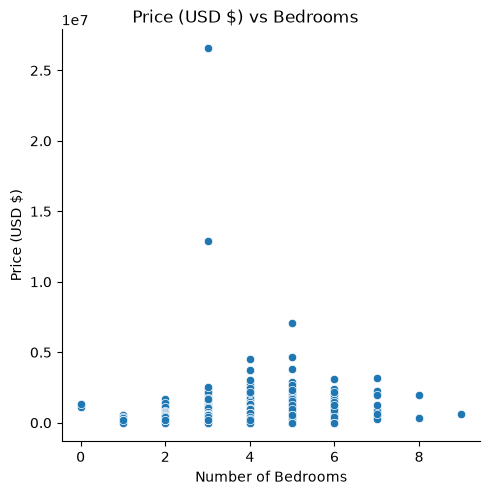

In [12]:
# Scatter plot of price vs bedrooms
scatter2 = sns.relplot(kind='scatter', x='bedrooms', y='price', data=df)
scatter2.fig.suptitle("Price (USD $) vs Bedrooms")
scatter2.set(xlabel="Number of Bedrooms", ylabel="Price (USD $)")
plt.show()

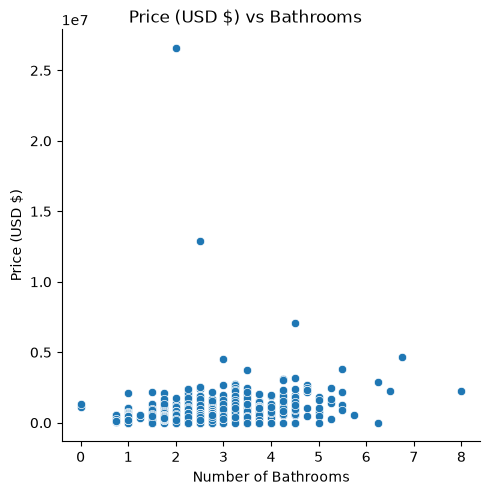

In [13]:
# Scatter plot of price vs bathrooms
scatter2 = sns.relplot(kind='scatter', x='bathrooms', y='price', data=df)
scatter2.fig.suptitle("Price (USD $) vs Bathrooms")
scatter2.set(xlabel="Number of Bathrooms", ylabel="Price (USD $)")
plt.show()

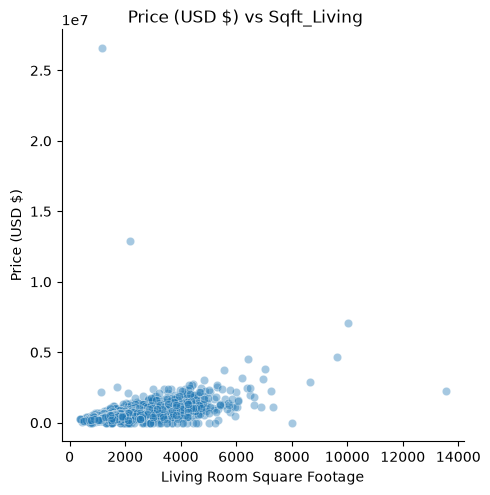

In [14]:
# Scatter plot of price vs sqft_living
scatter1 = sns.relplot(kind='scatter', x='sqft_living', y='price', alpha=0.4, data=df)
scatter1.fig.suptitle("Price (USD $) vs Sqft_Living")
scatter1.set(xlabel="Living Room Square Footage", ylabel="Price (USD $)")
plt.show()

### 2.3 Correlation Heatmap

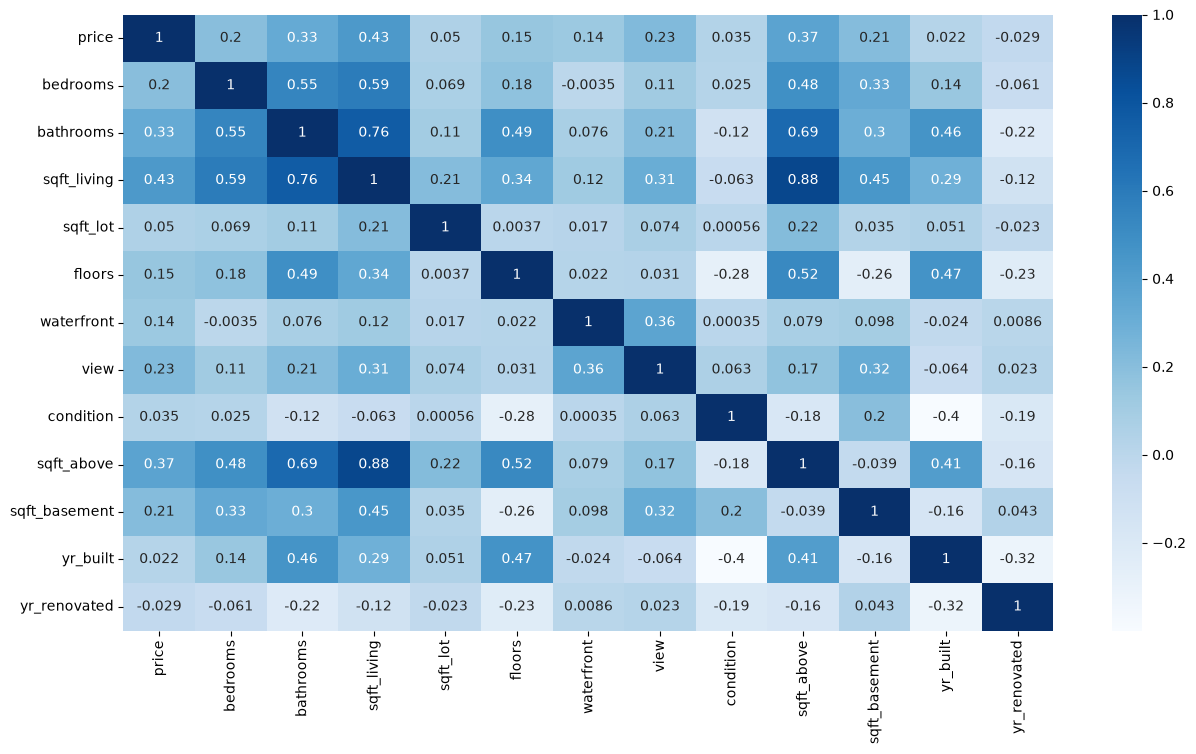

In [15]:
# Correlation heatmap of numeric features
fig, ax = plt.subplots(figsize=(15, 8))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='Blues', ax=ax)
plt.show()

## Section 3: Multiple Linear Regression Model
- Selecting feature variables (bathrooms, sqft_living, sqft_above, sqft_basement)
- Fixing outlier values
- Splitting and training multiple linear regression model
- Equations and coefficients

### 3.1 Feature Selection & Outlier Removal

In [16]:
# Feature selection
new_data = df[['price', 'statezip', 'sqft_living', 'floors', 'bedrooms', 'bathrooms']].copy()
new_data.head()

,price,statezip,sqft_living,floors,bedrooms,bathrooms
0,313000.0,WA 98133,1340,1.5,3.0,1.50
1,2384000.0,WA 98119,3650,2.0,5.0,2.50
2,342000.0,WA 98042,1930,1.0,3.0,2.00
3,420000.0,WA 98008,2000,1.0,3.0,2.25
4,550000.0,WA 98052,1940,1.0,4.0,2.50


In [17]:
# Filtering out the outliers and non-zero prices
thresholds = calc_outliers(new_data['price'])

new_data = new_data[(new_data['price'] < thresholds[0]) & (new_data['price'] > thresholds[1])]
new_data = new_data[new_data['price'] > 0]
len(new_data)

4311

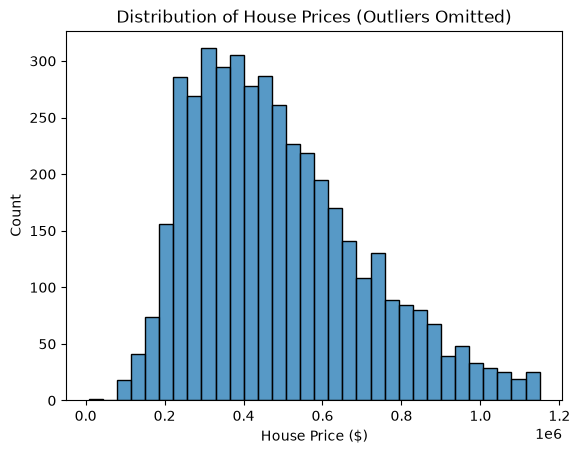

In [18]:
# Histogram of the new_data prices
new_price_hist = sns.histplot(x='price', data=new_data)
new_price_hist.set_title("Distribution of House Prices (Outliers Omitted)")
new_price_hist.set(xlabel="House Price ($)", ylabel="Count")

plt.show()

In [19]:
# Centers of measure for target variable: price
new_data['price'].agg([np.mean, np.median])

mean      487456.901904
median    450000.000000
Name: price, dtype: float64

### 3.2 Fitting The Model

In [20]:
# Splitting the features with the target variable
X_features = new_data.drop('price', axis=1)
X_features = pd.get_dummies(X_features, columns=['statezip'], drop_first=True) # One-hot encoding statezip to be numeric
y_price = new_data['price']

# Creating the train-test split (80-20)
X_train, X_test, y_train, y_test = train_test_split(X_features, y_price, test_size=0.2, random_state=42)

In [21]:
# Features post one-hot encoding
X_features.head()

,sqft_living,floors,bedrooms,bathrooms,statezip_WA 98002,statezip_WA 98003,statezip_WA 98004,statezip_WA 98005,statezip_WA 98006,statezip_WA 98007,...,statezip_WA 98155,statezip_WA 98166,statezip_WA 98168,statezip_WA 98177,statezip_WA 98178,statezip_WA 98188,statezip_WA 98198,statezip_WA 98199,statezip_WA 98288,statezip_WA 98354
0,1340,1.5,3.0,1.50,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,1930,1.0,3.0,2.00,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,2000,1.0,3.0,2.25,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4,1940,1.0,4.0,2.50,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
5,880,1.0,2.0,1.00,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


In [22]:
# Creating the logistic regression model
multi_lr_model = LinearRegression()

# Fitting the model
multi_lr_model.fit(X_train, y_train)

# Creating the predictions
predictions = multi_lr_model.predict(X_test)

### 3.3 Linear Regression Equation

In [23]:
coefficients = multi_lr_model.coef_
intercept = multi_lr_model.intercept_

print(f"w = {coefficients:}, b = {intercept:0.2f}")

w = [ 1.59e+02 -5.34e+03 -1.27e+04  1.34e+04  6.24e+02  1.69e+04  5.17e+05
  3.54e+05  3.15e+05  3.22e+05  2.28e+05  1.74e+05  1.33e+05  1.29e+05
  8.66e+04  4.06e+04 -1.49e+04  1.80e+05  1.80e+05  1.41e+05  2.59e+05
  8.22e+03  1.37e+04 -1.06e+04  3.59e+05  2.01e+05  3.33e+04  2.62e-09
  4.24e+05  5.82e+03  1.01e+05  1.06e+04  2.13e+05  1.16e+05  2.96e+05
  2.68e+05  5.15e+04  1.24e+05  2.31e+04  4.48e+04  1.28e+05  1.46e+05
  2.07e+05  1.99e+05  2.17e+05  2.46e+05  2.92e+05  2.18e+05  1.79e+03
  3.78e+05  3.29e+05  4.08e+05  1.00e+05  3.32e+05  1.15e+05  4.96e+05
  4.44e+05  3.06e+05  3.26e+05  3.00e+05  1.70e+05  4.36e+05  3.47e+05
  1.65e+05  2.00e+05  1.37e+05  2.71e+05  2.50e+05  1.35e+05  5.92e+04
  1.46e+05  1.43e+05  3.07e+04  2.66e+05  2.34e+04  4.98e+03  4.33e+04
  3.55e+05  4.17e+04  1.09e+05], b = -3791.66


In [24]:
# Multiple linear regression equation
print(f"price = {multi_lr_model.intercept_:.4f}")
for c, n in zip(multi_lr_model.coef_, X_train.columns):
    print(f"   {c:+.4f} * {n}")

price = -3791.6591
   +158.9683 * sqft_living
   -5340.7584 * floors
   -12737.0702 * bedrooms
   +13385.3610 * bathrooms
   +623.6373 * statezip_WA 98002
   +16868.0909 * statezip_WA 98003
   +517023.2020 * statezip_WA 98004
   +354059.7602 * statezip_WA 98005
   +315117.6520 * statezip_WA 98006
   +322123.3589 * statezip_WA 98007
   +228423.5199 * statezip_WA 98008
   +173900.0470 * statezip_WA 98010
   +133403.7605 * statezip_WA 98011
   +128614.1698 * statezip_WA 98014
   +86635.3891 * statezip_WA 98019
   +40617.1479 * statezip_WA 98022
   -14874.7989 * statezip_WA 98023
   +179791.1862 * statezip_WA 98024
   +180087.1278 * statezip_WA 98027
   +140873.6220 * statezip_WA 98028
   +259238.4414 * statezip_WA 98029
   +8216.1743 * statezip_WA 98030
   +13715.4465 * statezip_WA 98031
   -10574.8141 * statezip_WA 98032
   +359261.3177 * statezip_WA 98033
   +200612.2046 * statezip_WA 98034
   +33294.4881 * statezip_WA 98038
   +0.0000 * statezip_WA 98039
   +423949.5297 * statezip_WA 9

## Section 4: Model Evaluation
- MSE & RSME Values
- Create equation (coefficients & intercept)

### 4.1 MSE, RMSE, R^2 Calculations

In [25]:
print(f"MSE: $^2 {round(mean_squared_error(y_test, predictions),2)}")
print(f"Root MSE: $ {round(root_mean_squared_error(y_test, predictions),2)}")

MSE: $^2 12315742356.09
Root MSE: $ 110976.31


In [26]:
print(f"R^2 Score: {round(r2_score(y_test, predictions),2)}")

R^2 Score: 0.74


### 4.2 Actual vs. Predicted Plot

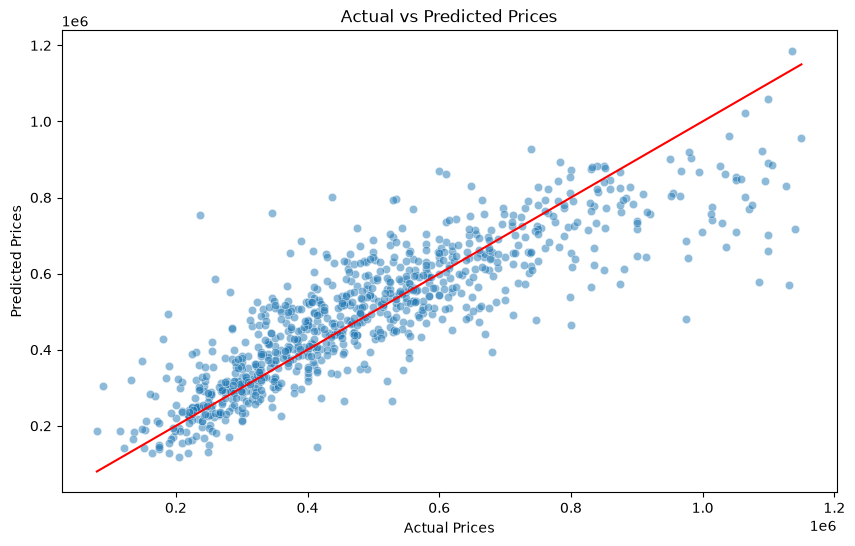

In [27]:
plt.figure(figsize=(10,6))
sns.scatterplot(x=y_test, y=predictions, alpha=0.5)
sns.lineplot(x=[y_test.min(), y_test.max()], y=[y_test.min(), y_test.max()], color='red')
plt.title('Actual vs Predicted Prices')
plt.xlabel('Actual Prices')
plt.ylabel('Predicted Prices')
plt.show()